# Stock Market Prediction using LSTM and GRU
**Module: Artificial Intelligence & Neural Networks — Assignment Task 1**

## 1. Setup and Imports

In [1]:
# If running on Google Colab, uncomment the line below
# !pip install tensorflow scikit-learn pandas matplotlib seaborn -q

import os
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

# Reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)

print('TensorFlow version:', tf.__version__)
print('GPU available:', tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Load the Dataset

The dataset `Stock_Price_Data_[3921].csv` contains daily stock market records with the columns:
`Date, Open, High, Low, Close, Adj Close, Volume`.

If you are on Google Colab, upload the CSV first using the cell below.

In [2]:
# --- Google Colab upload (uncomment if needed) ---
# from google.colab import files
# uploaded = files.upload()

CSV_PATH = '/kaggle/input/datasets/arslanbhutto/stock-pred/Stock_Price_Data_3921.csv'   # change path if required

df = pd.read_csv(CSV_PATH)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

print('Shape:', df.shape)
print('Date range:', df['Date'].min().date(), 'to', df['Date'].max().date())
df.head()

Shape: (9909, 7)
Date range: 1980-12-12 to 2020-04-01


,Date,Open,High,Low,Close,Adj Close,Volume
0,1980-12-12,0.513393,0.515625,0.513393,0.513393,0.406782,117258400
1,1980-12-15,0.488839,0.488839,0.486607,0.486607,0.385558,43971200
2,1980-12-16,0.453125,0.453125,0.450893,0.450893,0.357260,26432000
3,1980-12-17,0.462054,0.464286,0.462054,0.462054,0.366103,21610400
4,1980-12-18,0.475446,0.477679,0.475446,0.475446,0.376715,18362400


In [3]:
# Structure, data types and missing values
df.info()
print('\nMissing values per column:')
print(df.isnull().sum())
print('\nDuplicated rows:', df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9909 entries, 0 to 9908
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       9909 non-null   datetime64[ns]
 1   Open       9909 non-null   float64       
 2   High       9909 non-null   float64       
 3   Low        9909 non-null   float64       
 4   Close      9909 non-null   float64       
 5   Adj Close  9909 non-null   float64       
 6   Volume     9909 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 542.0 KB

Missing values per column:
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

Duplicated rows: 0


In [4]:
# Statistical summary
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,9909,2000-07-30 08:33:08.010899200,1980-12-12 00:00:00,1990-10-02 00:00:00,2000-07-21 00:00:00,2010-05-28 00:00:00,2020-04-01 00:00:00,NaN
Open,9909.0,32.606849,0.198661,1.071429,1.729286,35.799999,324.73999,58.415759
High,9909.0,32.936079,0.198661,1.089286,1.758929,36.265713,327.850006,59.001576
Low,9909.0,32.27756,0.196429,1.048571,1.696429,35.328571,323.350006,57.883037
Close,9909.0,32.61803,0.196429,1.071429,1.732143,35.761429,327.200012,58.471899
Adj Close,9909.0,30.57657,0.155638,0.917643,1.466154,31.042374,327.200012,56.746275
Volume,9909.0,85829159.299627,347200.0,33042300.0,57664900.0,106999200.0,1855410200.0,85971948.761355


## 3. Exploratory Data Analysis (EDA)

We inspect the trend, distribution, volatility and correlation structure of the data to justify our feature and model design choices.

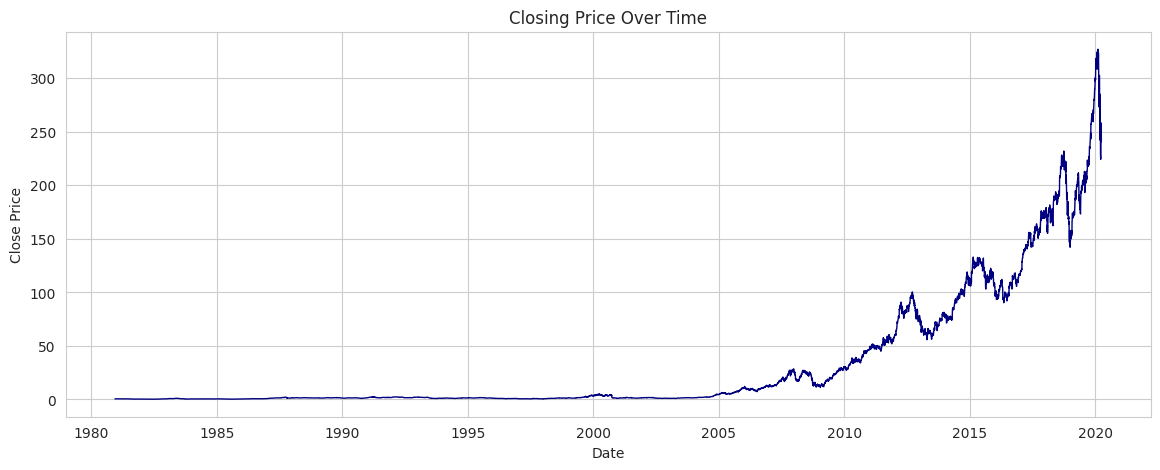

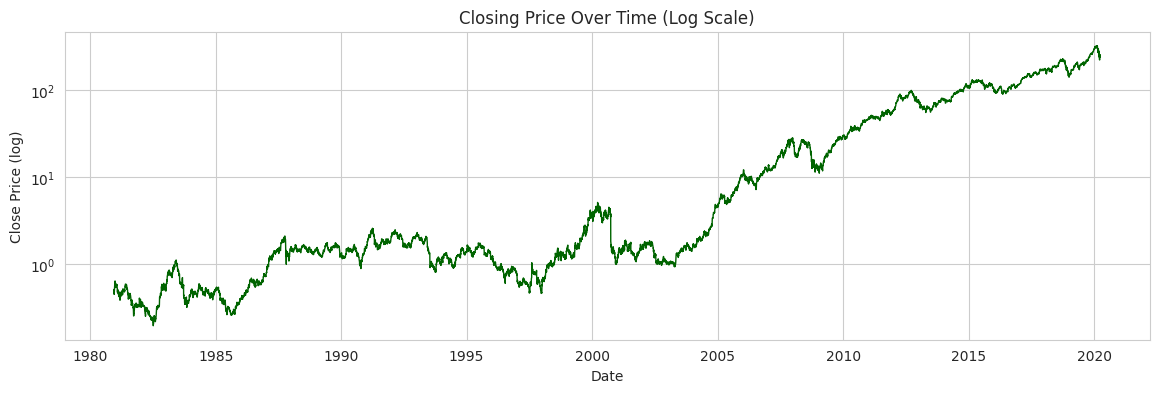

In [5]:
# 3.1 Closing price over time
plt.figure(figsize=(14,5))
plt.plot(df['Date'], df['Close'], color='navy', linewidth=1)
plt.title('Closing Price Over Time')
plt.xlabel('Date'); plt.ylabel('Close Price')
plt.show()

# Log scale view (long history spans several orders of magnitude)
plt.figure(figsize=(14,4))
plt.semilogy(df['Date'], df['Close'], color='darkgreen', linewidth=1)
plt.title('Closing Price Over Time (Log Scale)')
plt.xlabel('Date'); plt.ylabel('Close Price (log)')
plt.show()

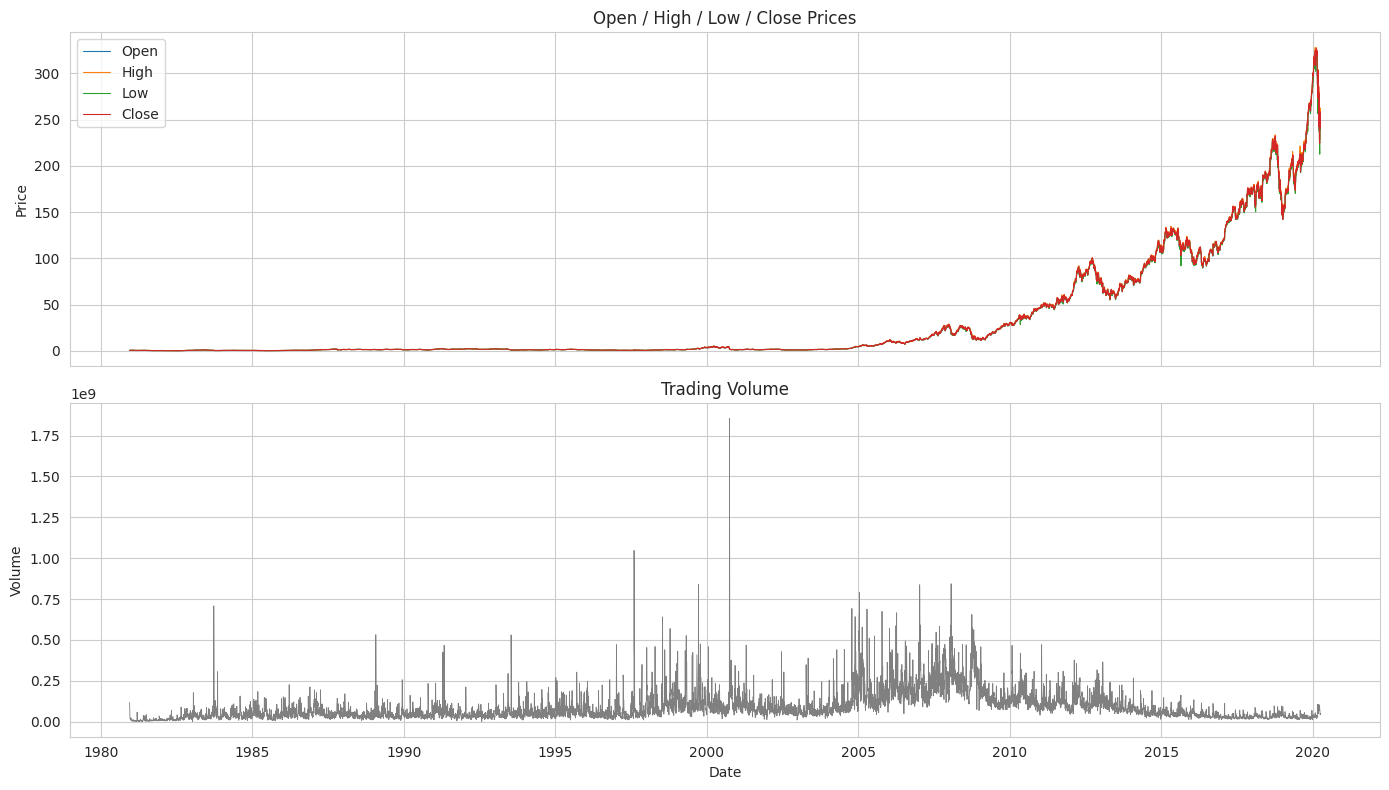

In [6]:
# 3.2 All OHLC prices and Volume
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for col in ['Open', 'High', 'Low', 'Close']:
    axes[0].plot(df['Date'], df[col], label=col, linewidth=0.8)
axes[0].set_title('Open / High / Low / Close Prices'); axes[0].legend(); axes[0].set_ylabel('Price')

axes[1].plot(df['Date'], df['Volume'], color='grey', linewidth=0.6)
axes[1].set_title('Trading Volume'); axes[1].set_ylabel('Volume'); axes[1].set_xlabel('Date')
plt.tight_layout(); plt.show()

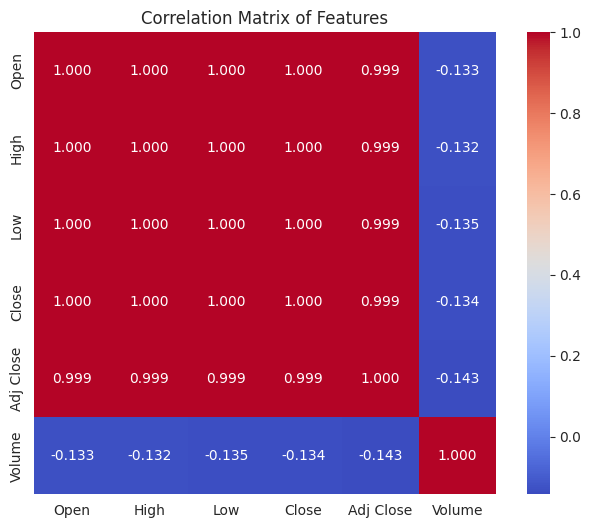

In [7]:
# 3.3 Correlation heatmap
plt.figure(figsize=(8,6))
corr = df[['Open','High','Low','Close','Adj Close','Volume']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.3f', square=True)
plt.title('Correlation Matrix of Features')
plt.show()

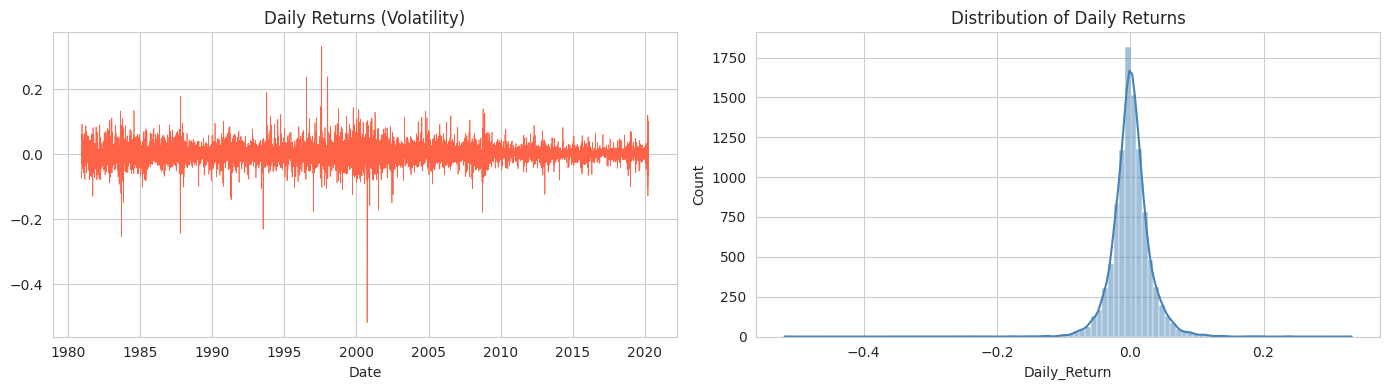

Mean daily return: 0.00104
Std  daily return: 0.02874


In [8]:
# 3.4 Daily returns and volatility
df['Daily_Return'] = df['Close'].pct_change()

fig, axes = plt.subplots(1, 2, figsize=(14,4))
axes[0].plot(df['Date'], df['Daily_Return'], color='tomato', linewidth=0.5)
axes[0].set_title('Daily Returns (Volatility)'); axes[0].set_xlabel('Date')

sns.histplot(df['Daily_Return'].dropna(), bins=100, kde=True, ax=axes[1], color='steelblue')
axes[1].set_title('Distribution of Daily Returns')
plt.tight_layout(); plt.show()

print('Mean daily return: %.5f' % df['Daily_Return'].mean())
print('Std  daily return: %.5f' % df['Daily_Return'].std())

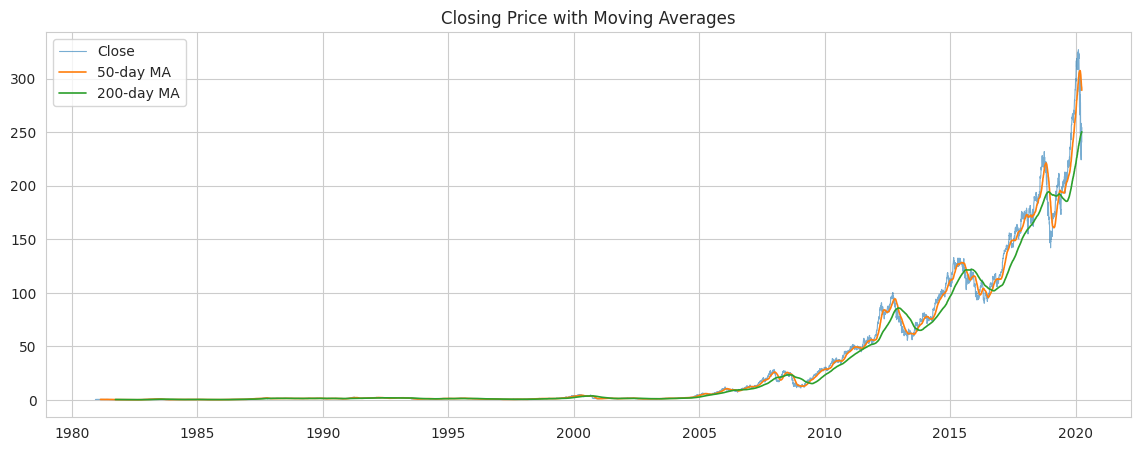

In [9]:
# 3.5 Moving averages - trend smoothing
df['MA50']  = df['Close'].rolling(50).mean()
df['MA200'] = df['Close'].rolling(200).mean()

plt.figure(figsize=(14,5))
plt.plot(df['Date'], df['Close'], label='Close', linewidth=0.8, alpha=0.6)
plt.plot(df['Date'], df['MA50'], label='50-day MA', linewidth=1.2)
plt.plot(df['Date'], df['MA200'], label='200-day MA', linewidth=1.2)
plt.title('Closing Price with Moving Averages'); plt.legend(); plt.show()

## 4. Data Preprocessing

In [10]:
LOOKBACK   = 60      # number of past days used as input sequence
HORIZON    = 1       # predict next day close
TARGET_COL = 'Close'
FEATURES   = ['Close']   # univariate configuration (multivariate tested in Section 11)

data = df[FEATURES].values.astype('float32')
print('Feature matrix shape:', data.shape)

Feature matrix shape: (9909, 1)


In [11]:
# 4.1 Chronological split BEFORE scaling (no shuffling - time series!)
n = len(data)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

train_raw = data[:train_end]
val_raw   = data[train_end - LOOKBACK:val_end]   # overlap so windows are complete
test_raw  = data[val_end - LOOKBACK:]

print('Train rows:', train_end)
print('Val   rows:', val_end - train_end)
print('Test  rows:', n - val_end)

Train rows: 6936
Val   rows: 1486
Test  rows: 1487


In [12]:
# 4.2 Fit scaler on TRAIN ONLY, then transform each split
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(train_raw)

train_scaled = scaler.transform(train_raw)
val_scaled   = scaler.transform(val_raw)
test_scaled  = scaler.transform(test_raw)

# Separate scaler for inverse-transforming the target only
target_idx = FEATURES.index(TARGET_COL)
target_scaler = MinMaxScaler(feature_range=(0,1))
target_scaler.fit(train_raw[:, [target_idx]])

print('Scaler fitted on train only. Train min/max:', scaler.data_min_, scaler.data_max_)

Scaler fitted on train only. Train min/max: [0.19642857] [28.547142]


In [13]:
# 4.3 Sliding-window sequence generator
def create_sequences(series, lookback=LOOKBACK, horizon=HORIZON, target_idx=0):
    X, y = [], []
    for i in range(lookback, len(series) - horizon + 1):
        X.append(series[i-lookback:i, :])
        y.append(series[i + horizon - 1, target_idx])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, target_idx=target_idx)
X_val,   y_val   = create_sequences(val_scaled,   target_idx=target_idx)
X_test,  y_test  = create_sequences(test_scaled,  target_idx=target_idx)

print('X_train:', X_train.shape, ' y_train:', y_train.shape)
print('X_val  :', X_val.shape,   ' y_val  :', y_val.shape)
print('X_test :', X_test.shape,  ' y_test :', y_test.shape)

X_train: (6876, 60, 1)  y_train: (6876,)
X_val  : (1486, 60, 1)  y_val  : (1486,)
X_test : (1487, 60, 1)  y_test : (1487,)


## 5. Visualising the Split

Confirms the split is chronological — the model never sees future data during training.

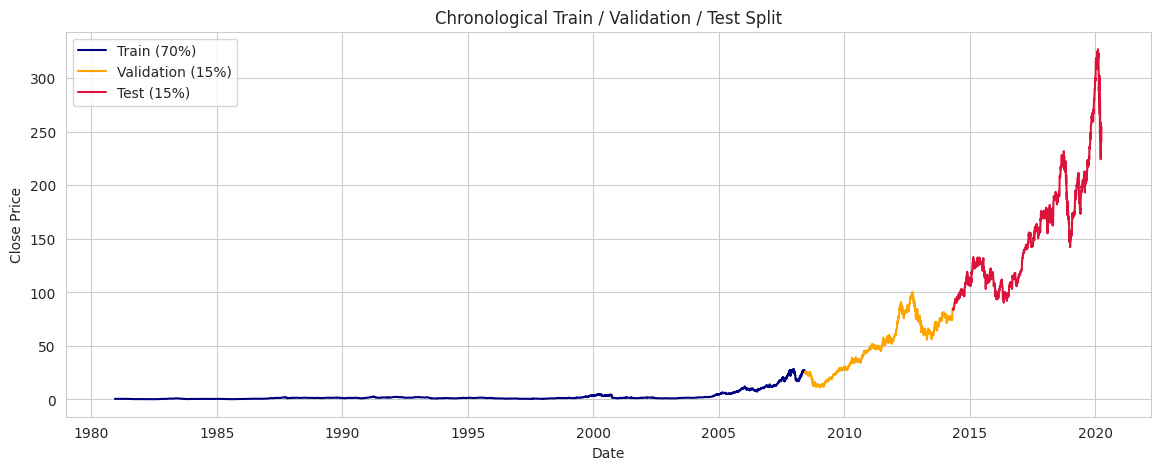

In [14]:
plt.figure(figsize=(14,5))
plt.plot(df['Date'][:train_end], df['Close'][:train_end], label='Train (70%)', color='navy')
plt.plot(df['Date'][train_end:val_end], df['Close'][train_end:val_end], label='Validation (15%)', color='orange')
plt.plot(df['Date'][val_end:], df['Close'][val_end:], label='Test (15%)', color='crimson')
plt.title('Chronological Train / Validation / Test Split')
plt.legend(); plt.xlabel('Date'); plt.ylabel('Close Price')
plt.show()

## 6. Model Builder Functions

In [15]:
def build_rnn(cell_type='LSTM', units=(64, 32), dropout=0.2, dense_units=16,
              learning_rate=0.001, input_shape=None):
    """Builds a stacked LSTM or GRU regressor with dropout regularisation."""
    Cell = LSTM if cell_type.upper() == 'LSTM' else GRU
    model = Sequential(name=f'{cell_type}_Model')
    model.add(Input(shape=input_shape))

    for i, u in enumerate(units):
        return_seq = (i < len(units) - 1)          # only last recurrent layer returns a vector
        model.add(Cell(u, return_sequences=return_seq, name=f'{cell_type.lower()}_{i+1}'))
        model.add(Dropout(dropout, name=f'dropout_{i+1}'))

    if dense_units:
        model.add(Dense(dense_units, activation='relu', name='dense_hidden'))
    model.add(Dense(1, activation='linear', name='output'))

    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='mse', metrics=['mae'])
    return model

INPUT_SHAPE = (X_train.shape[1], X_train.shape[2])
print('Input shape:', INPUT_SHAPE)

Input shape: (60, 1)


In [16]:
# Callbacks: Early Stopping + LR reduction (generalisation / overfitting control)
def get_callbacks(name):
    return [
        EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
        ModelCheckpoint(f'best_{name}.keras', monitor='val_loss', save_best_only=True, verbose=0)
    ]

EPOCHS = 100
BATCH_SIZE = 32

## 7. Baseline LSTM Model

In [17]:
lstm_model = build_rnn('LSTM', units=(64,32), dropout=0.2, input_shape=INPUT_SHAPE)
lstm_model.summary()

I0000 00:00:1784239658.020170      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1784239658.023180      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "LSTM_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
history_lstm = lstm_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks('lstm'),
    shuffle=False,     # preserve temporal order
    verbose=1
)

Epoch 1/100
215/215 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 0.0016 - mae: 0.0205 - val_loss: 1.3348 - val_mae: 0.9357 - learning_rate: 0.0010
Epoch 2/100
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0070 - mae: 0.0457 - val_loss: 1.3156 - val_mae: 0.9164 - learning_rate: 0.0010
Epoch 3/100
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0097 - mae: 0.0532 - val_loss: 1.2798 - val_mae: 0.9031 - learning_rate: 0.0010
Epoch 4/100
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0104 - mae: 0.0563 - val_loss: 1.1543 - val_mae: 0.8601 - learning_rate: 0.0010
Epoch 5/100
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0070 - mae: 0.0472 - val_loss: 1.1740 - val_mae: 0.8482 - learning_rate: 0.0010
Epoch 6/100
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0024 - mae: 0.0312 - val_loss: 0.9672 - val_mae: 0.7558 - learning_rate: 0.0010
Epoch 7/100
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0011 - mae: 0.0212 - val_loss: 0.9169 - val_mae: 0.7247 - learning_rate:

## 8. Baseline GRU Model

In [19]:
gru_model = build_rnn('GRU', units=(64,32), dropout=0.2, input_shape=INPUT_SHAPE)
gru_model.summary()

Model: "GRU_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_1 (GRU)                     │ (None, 60, 64)         │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,817 (89.13 KB)

 Trainable params: 22,817 (89.13 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
history_gru = gru_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks('gru'),
    shuffle=False,
    verbose=1
)

Epoch 1/100
215/215 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.0018 - mae: 0.0224 - val_loss: 1.1667 - val_mae: 0.8641 - learning_rate: 0.0010
Epoch 2/100
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0058 - mae: 0.0427 - val_loss: 1.0623 - val_mae: 0.8280 - learning_rate: 0.0010
Epoch 3/100
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0068 - mae: 0.0457 - val_loss: 0.9312 - val_mae: 0.7756 - learning_rate: 0.0010
Epoch 4/100
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0088 - mae: 0.0555 - val_loss: 0.2793 - val_mae: 0.4066 - learning_rate: 0.0010
Epoch 5/100
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0063 - mae: 0.0474 - val_loss: 0.3673 - val_mae: 0.4592 - learning_rate: 0.0010
Epoch 6/100
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0042 - mae: 0.0402 - val_loss: 0.4730 - val_mae: 0.5168 - learning_rate: 0.0010
Epoch 7/100
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0019 - mae: 0.0284 - val_loss: 0.4329 - val_mae: 0.4825 - learning_rate:

## 9. Learning Curves — Overfitting Check

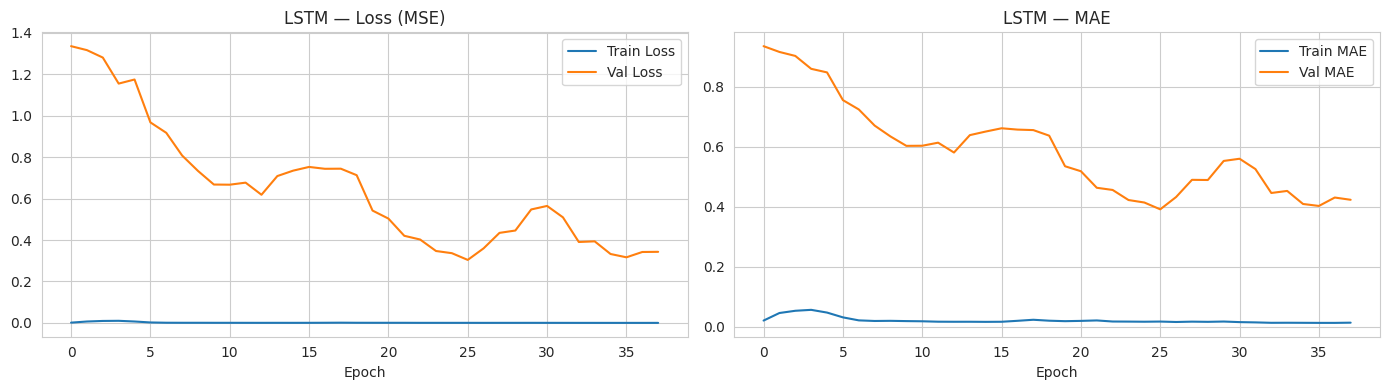

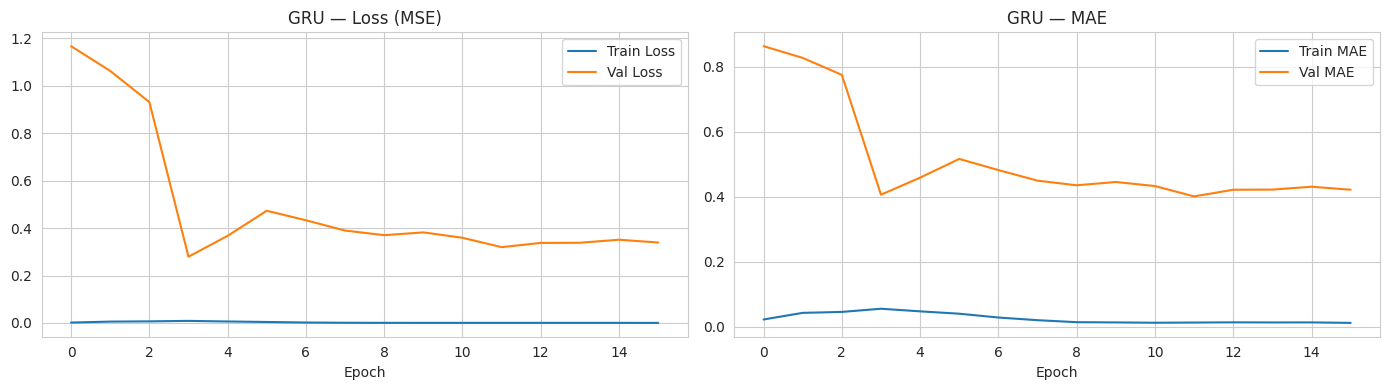

In [21]:
def plot_history(hist, title):
    fig, axes = plt.subplots(1, 2, figsize=(14,4))
    axes[0].plot(hist.history['loss'], label='Train Loss')
    axes[0].plot(hist.history['val_loss'], label='Val Loss')
    axes[0].set_title(f'{title} — Loss (MSE)'); axes[0].set_xlabel('Epoch'); axes[0].legend()

    axes[1].plot(hist.history['mae'], label='Train MAE')
    axes[1].plot(hist.history['val_mae'], label='Val MAE')
    axes[1].set_title(f'{title} — MAE'); axes[1].set_xlabel('Epoch'); axes[1].legend()
    plt.tight_layout(); plt.show()

plot_history(history_lstm, 'LSTM')
plot_history(history_gru, 'GRU')

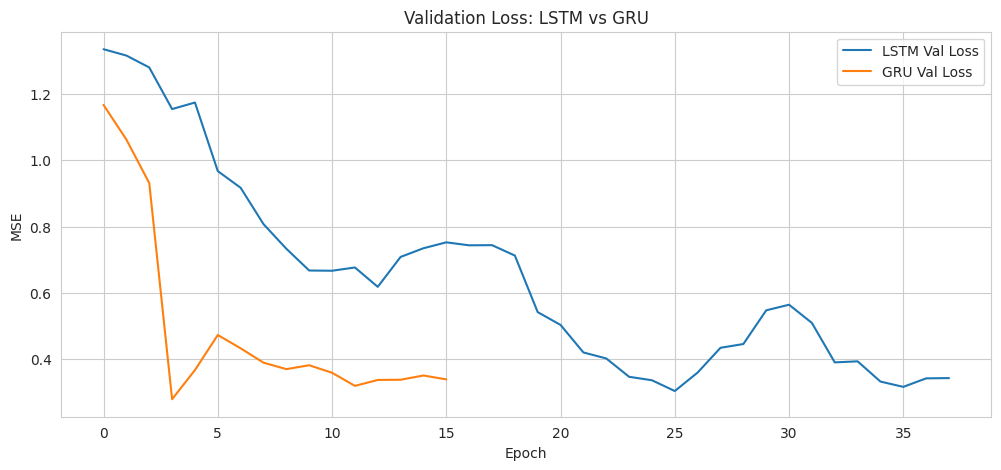

LSTM best val_loss: 0.304064 (epoch 26)
GRU  best val_loss: 0.279331 (epoch 4)


In [22]:
# Side-by-side validation loss comparison
plt.figure(figsize=(12,5))
plt.plot(history_lstm.history['val_loss'], label='LSTM Val Loss')
plt.plot(history_gru.history['val_loss'],  label='GRU Val Loss')
plt.title('Validation Loss: LSTM vs GRU'); plt.xlabel('Epoch'); plt.ylabel('MSE')
plt.legend(); plt.show()

print('LSTM best val_loss: %.6f (epoch %d)' % (min(history_lstm.history['val_loss']),
                                               int(np.argmin(history_lstm.history['val_loss']))+1))
print('GRU  best val_loss: %.6f (epoch %d)' % (min(history_gru.history['val_loss']),
                                               int(np.argmin(history_gru.history['val_loss']))+1))

## 10. Evaluation Metrics

In [23]:
def inverse_target(y_scaled):
    return target_scaler.inverse_transform(np.array(y_scaled).reshape(-1,1)).flatten()

def directional_accuracy(y_true, y_pred):
    true_dir = np.sign(np.diff(y_true))
    pred_dir = np.sign(np.diff(y_pred))
    return np.mean(true_dir == pred_dir) * 100

def evaluate(model, X, y_true_scaled, name=''):
    pred_scaled = model.predict(X, verbose=0).flatten()
    y_true = inverse_target(y_true_scaled)
    y_pred = inverse_target(pred_scaled)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2   = r2_score(y_true, y_pred)
    da   = directional_accuracy(y_true, y_pred)

    return {'Model': name, 'RMSE': rmse, 'MAE': mae, 'MAPE (%)': mape,
            'R2': r2, 'Directional Acc (%)': da}, y_true, y_pred

In [24]:
res_lstm, y_true_test, y_pred_lstm = evaluate(lstm_model, X_test, y_test, 'LSTM (baseline)')
res_gru,  _,           y_pred_gru  = evaluate(gru_model,  X_test, y_test, 'GRU (baseline)')

baseline_results = pd.DataFrame([res_lstm, res_gru])
baseline_results.round(4)

,Model,RMSE,MAE,MAPE (%),R2,Directional Acc (%)
0,LSTM (baseline),106.3176,93.1445,56.557800,-2.9863,51.6824
1,GRU (baseline),103.0224,90.0626,54.596901,-2.7430,50.6057


In [25]:
# Also report train/val metrics to expose any overfitting gap
rows = []
for mdl, nm in [(lstm_model,'LSTM'), (gru_model,'GRU')]:
    for X_, y_, split in [(X_train,y_train,'Train'), (X_val,y_val,'Val'), (X_test,y_test,'Test')]:
        r,_,_ = evaluate(mdl, X_, y_, f'{nm} - {split}')
        rows.append(r)
pd.DataFrame(rows).round(4)

,Model,RMSE,MAE,MAPE (%),R2,Directional Acc (%)
0,LSTM - Train,0.5106,0.3896,52.273399,0.9876,46.7055
1,LSTM - Val,15.6331,11.1000,16.637501,0.5722,51.1111
2,LSTM - Test,106.3176,93.1445,56.557800,-2.9863,51.6824
3,GRU - Train,9.2441,9.2024,963.205627,-3.0489,46.0218
4,GRU - Val,14.9839,11.5287,23.054600,0.6070,52.9966
5,GRU - Test,103.0224,90.0626,54.596901,-2.7430,50.6057


## 11. Prediction Visualisations

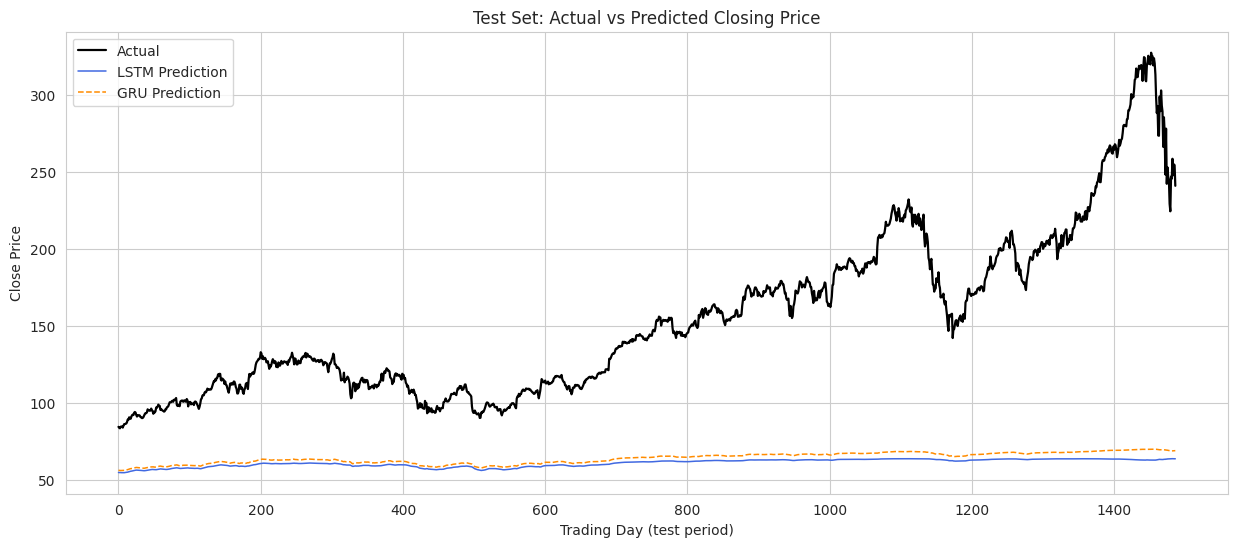

In [26]:
plt.figure(figsize=(15,6))
plt.plot(y_true_test, label='Actual', color='black', linewidth=1.6)
plt.plot(y_pred_lstm, label='LSTM Prediction', color='royalblue', linewidth=1.1)
plt.plot(y_pred_gru,  label='GRU Prediction',  color='darkorange', linewidth=1.1, linestyle='--')
plt.title('Test Set: Actual vs Predicted Closing Price')
plt.xlabel('Trading Day (test period)'); plt.ylabel('Close Price')
plt.legend(); plt.show()

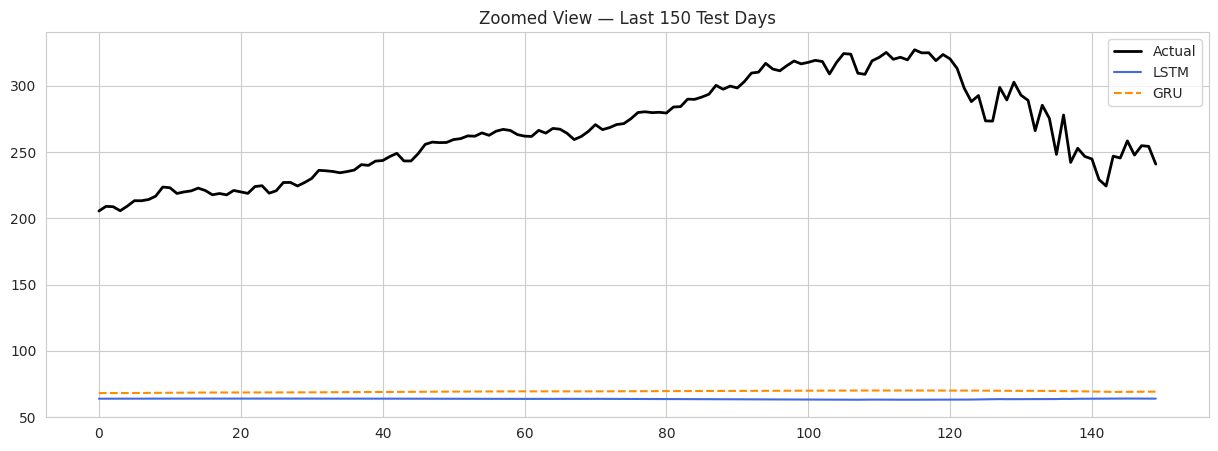

In [27]:
# Zoomed view of the last 150 test days
k = 150
plt.figure(figsize=(15,5))
plt.plot(y_true_test[-k:], label='Actual', color='black', linewidth=2)
plt.plot(y_pred_lstm[-k:], label='LSTM', color='royalblue')
plt.plot(y_pred_gru[-k:],  label='GRU',  color='darkorange', linestyle='--')
plt.title(f'Zoomed View — Last {k} Test Days'); plt.legend(); plt.show()

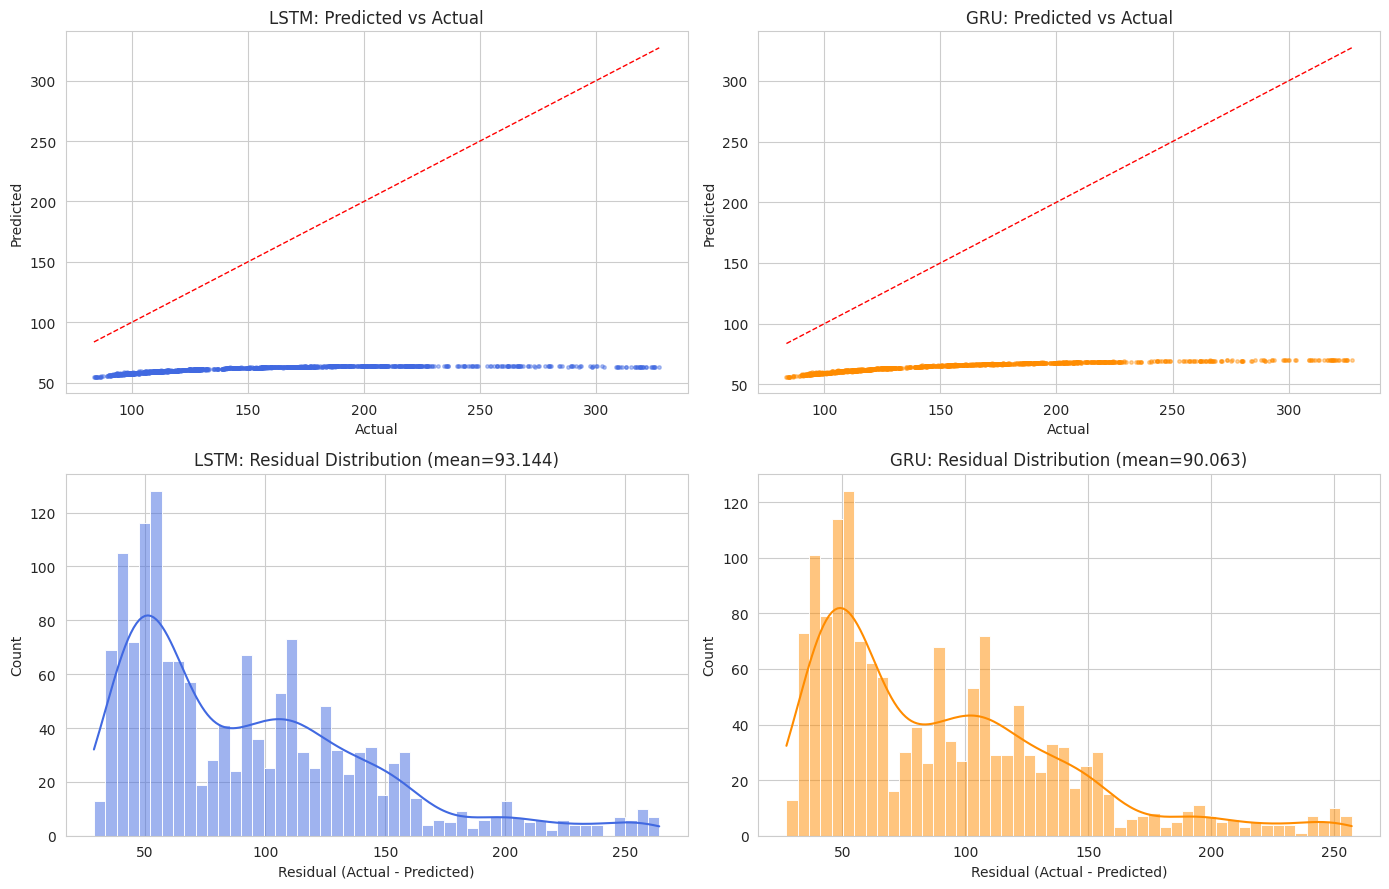

In [28]:
# Scatter (predicted vs actual) and residual distribution
fig, axes = plt.subplots(2, 2, figsize=(14,9))

for ax, y_pred, nm, c in [(axes[0,0], y_pred_lstm, 'LSTM', 'royalblue'),
                          (axes[0,1], y_pred_gru,  'GRU',  'darkorange')]:
    ax.scatter(y_true_test, y_pred, s=6, alpha=0.4, color=c)
    lims = [y_true_test.min(), y_true_test.max()]
    ax.plot(lims, lims, 'r--', linewidth=1)
    ax.set_title(f'{nm}: Predicted vs Actual'); ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')

for ax, y_pred, nm, c in [(axes[1,0], y_pred_lstm, 'LSTM', 'royalblue'),
                          (axes[1,1], y_pred_gru,  'GRU',  'darkorange')]:
    resid = y_true_test - y_pred
    sns.histplot(resid, bins=50, kde=True, ax=ax, color=c)
    ax.set_title(f'{nm}: Residual Distribution (mean={resid.mean():.3f})')
    ax.set_xlabel('Residual (Actual - Predicted)')

plt.tight_layout(); plt.show()

## 12. Hyperparameter Tuning / Configuration Experiments

In [29]:
TUNE_EPOCHS = 40   # shorter budget for the search

configs = [
    # name,                 cell,   units,      dropout, lr,     batch
    ('LSTM u32 d0.2',       'LSTM', (32,),      0.2,     0.001,  32),
    ('LSTM u64-32 d0.0',    'LSTM', (64,32),    0.0,     0.001,  32),
    ('LSTM u64-32 d0.2',    'LSTM', (64,32),    0.2,     0.001,  32),
    ('LSTM u64-32 d0.3',    'LSTM', (64,32),    0.3,     0.001,  32),
    ('LSTM u128-64 d0.2',   'LSTM', (128,64),   0.2,     0.0005, 64),
    ('GRU  u32 d0.2',       'GRU',  (32,),      0.2,     0.001,  32),
    ('GRU  u64-32 d0.0',    'GRU',  (64,32),    0.0,     0.001,  32),
    ('GRU  u64-32 d0.2',    'GRU',  (64,32),    0.2,     0.001,  32),
    ('GRU  u64-32 d0.3',    'GRU',  (64,32),    0.3,     0.001,  32),
    ('GRU  u128-64 d0.2',   'GRU',  (128,64),   0.2,     0.0005, 64),
]

tune_records = []
tuned_models = {}

for name, cell, units, dr, lr, bs in configs:
    print('\n' + '='*60)
    print('Training config:', name)
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)

    m = build_rnn(cell, units=units, dropout=dr, learning_rate=lr, input_shape=INPUT_SHAPE)
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val),
              epochs=TUNE_EPOCHS, batch_size=bs, shuffle=False, verbose=0,
              callbacks=[EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)])

    val_res, _, _ = evaluate(m, X_val, y_val, name)
    val_res['Params'] = m.count_params()
    val_res['Epochs Run'] = len(h.history['loss'])
    tune_records.append(val_res)
    tuned_models[name] = m
    print('  -> Val RMSE: %.4f | Val MAPE: %.3f%%' % (val_res['RMSE'], val_res['MAPE (%)']))

tune_df = pd.DataFrame(tune_records).sort_values('RMSE').reset_index(drop=True)
tune_df.round(4)


Training config: LSTM u32 d0.2
  -> Val RMSE: 2.9739 | Val MAPE: 7.335%

Training config: LSTM u64-32 d0.0
  -> Val RMSE: 20.9700 | Val MAPE: 24.122%

Training config: LSTM u64-32 d0.2
  -> Val RMSE: 30.0045 | Val MAPE: 39.090%

Training config: LSTM u64-32 d0.3
  -> Val RMSE: 26.7038 | Val MAPE: 31.819%

Training config: LSTM u128-64 d0.2
  -> Val RMSE: 11.1098 | Val MAPE: 12.409%

Training config: GRU  u32 d0.2
  -> Val RMSE: 6.3815 | Val MAPE: 6.929%

Training config: GRU  u64-32 d0.0
  -> Val RMSE: 9.0363 | Val MAPE: 8.470%

Training config: GRU  u64-32 d0.2
  -> Val RMSE: 7.1288 | Val MAPE: 8.568%

Training config: GRU  u64-32 d0.3
  -> Val RMSE: 16.5957 | Val MAPE: 19.327%

Training config: GRU  u128-64 d0.2
  -> Val RMSE: 1.6133 | Val MAPE: 2.545%


,Model,RMSE,MAE,MAPE (%),R2,Directional Acc (%),Params,Epochs Run
0,GRU u128-64 d0.2,1.6133,1.1732,2.544800,0.9954,52.9966,88609,26
1,LSTM u32 d0.2,2.9739,2.6950,7.335000,0.9845,52.6599,4897,40
2,GRU u32 d0.2,6.3815,4.5298,6.929100,0.9287,51.5825,3905,29
3,GRU u64-32 d0.2,7.1288,4.7348,8.567800,0.9110,51.3805,22817,33
4,GRU u64-32 d0.0,9.0363,5.8120,8.469900,0.8571,51.2458,22817,30
5,LSTM u128-64 d0.2,11.1098,7.9979,12.409000,0.7839,50.9764,117025,14
6,GRU u64-32 d0.3,16.5957,12.2844,19.326599,0.5179,51.5825,22817,17
7,LSTM u64-32 d0.0,20.9700,15.5369,24.121901,0.2302,52.7946,29857,19
8,LSTM u64-32 d0.3,26.7038,20.3835,31.819201,-0.2483,50.9764,29857,22
9,LSTM u64-32 d0.2,30.0045,23.6622,39.090302,-0.5760,49.9663,29857,9


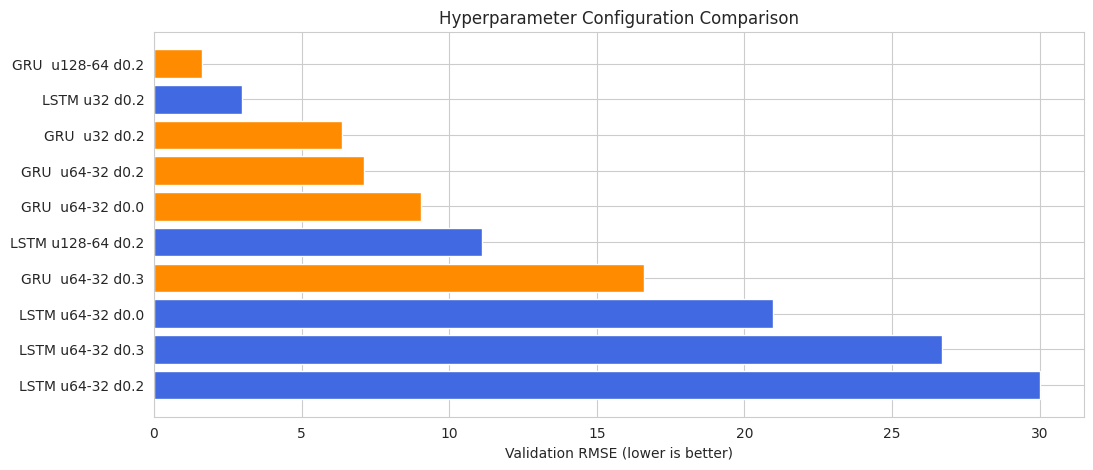

Best configuration on validation set: GRU  u128-64 d0.2


In [30]:
# Visualise the tuning results
plt.figure(figsize=(12,5))
colors = ['royalblue' if n.startswith('LSTM') else 'darkorange' for n in tune_df['Model']]
plt.barh(tune_df['Model'], tune_df['RMSE'], color=colors)
plt.xlabel('Validation RMSE (lower is better)')
plt.title('Hyperparameter Configuration Comparison')
plt.gca().invert_yaxis()
plt.show()

BEST_NAME = tune_df.iloc[0]['Model']
print('Best configuration on validation set:', BEST_NAME)

In [31]:
# 12.2 Effect of the lookback window length
lookback_records = []

for lb in [30, 60, 90]:
    Xtr, ytr = create_sequences(train_scaled, lookback=lb, target_idx=target_idx)
    # rebuild val/test raw slices for this lookback
    v_raw = data[train_end-lb:val_end]
    t_raw = data[val_end-lb:]
    Xv, yv = create_sequences(scaler.transform(v_raw), lookback=lb, target_idx=target_idx)

    tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
    m = build_rnn('GRU', units=(64,32), dropout=0.2, input_shape=(lb, Xtr.shape[2]))
    m.fit(Xtr, ytr, validation_data=(Xv, yv), epochs=30, batch_size=32, shuffle=False, verbose=0,
          callbacks=[EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)])
    r, _, _ = evaluate(m, Xv, yv, f'GRU lookback={lb}')
    lookback_records.append(r)
    print('lookback %d -> Val RMSE %.4f' % (lb, r['RMSE']))

pd.DataFrame(lookback_records).round(4)

lookback 30 -> Val RMSE 16.4087
lookback 60 -> Val RMSE 9.8414
lookback 90 -> Val RMSE 17.7611


,Model,RMSE,MAE,MAPE (%),R2,Directional Acc (%)
0,GRU lookback=30,16.4087,11.6304,17.286501,0.5287,52.9293
1,GRU lookback=60,9.8414,6.5732,9.656800,0.8304,52.3232
2,GRU lookback=90,17.7611,13.4815,24.660601,0.4478,53.1987


In [32]:
# 12.3 Multivariate configuration (does adding OHLC + Volume help?)
MULTI_FEATURES = ['Open','High','Low','Close','Volume']
mdata = df[MULTI_FEATURES].values.astype('float32')

m_train_raw = mdata[:train_end]
m_val_raw   = mdata[train_end-LOOKBACK:val_end]
m_test_raw  = mdata[val_end-LOOKBACK:]

mscaler = MinMaxScaler().fit(m_train_raw)
m_tidx  = MULTI_FEATURES.index('Close')

Xm_tr, ym_tr = create_sequences(mscaler.transform(m_train_raw), target_idx=m_tidx)
Xm_v,  ym_v  = create_sequences(mscaler.transform(m_val_raw),   target_idx=m_tidx)
Xm_te, ym_te = create_sequences(mscaler.transform(m_test_raw),  target_idx=m_tidx)

mtarget_scaler = MinMaxScaler().fit(m_train_raw[:, [m_tidx]])

tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
multi_model = build_rnn('GRU', units=(64,32), dropout=0.2,
                        input_shape=(Xm_tr.shape[1], Xm_tr.shape[2]))
multi_model.fit(Xm_tr, ym_tr, validation_data=(Xm_v, ym_v), epochs=40, batch_size=32,
                shuffle=False, verbose=0,
                callbacks=[EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)])

# evaluate using the multivariate target scaler
pred = mtarget_scaler.inverse_transform(multi_model.predict(Xm_v, verbose=0).reshape(-1,1)).flatten()
true = mtarget_scaler.inverse_transform(ym_v.reshape(-1,1)).flatten()
print('Multivariate GRU  -> Val RMSE: %.4f | MAPE: %.3f%%' % (
    np.sqrt(mean_squared_error(true, pred)),
    np.mean(np.abs((true-pred)/true))*100))
print('(Compare against the univariate GRU val RMSE from the table above.)')

Multivariate GRU  -> Val RMSE: 25.2589 | MAPE: 29.776%
(Compare against the univariate GRU val RMSE from the table above.)


## 13. Fine-Tuning the Best Model

Fine-tuning: GRU  u128-64 d0.2 | cell=GRU units=(128, 64) dropout=0.2
Epoch 1/150
108/108 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0030 - mae: 0.0300 - val_loss: 0.8054 - val_mae: 0.6944 - learning_rate: 5.0000e-04
Epoch 2/150
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0137 - mae: 0.0649 - val_loss: 0.6057 - val_mae: 0.6071 - learning_rate: 5.0000e-04
Epoch 3/150
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0045 - mae: 0.0330 - val_loss: 0.2456 - val_mae: 0.3781 - learning_rate: 5.0000e-04
Epoch 4/150
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 5.4972e-04 - mae: 0.0133 - val_loss: 0.3898 - val_mae: 0.4737 - learning_rate: 5.0000e-04
Epoch 5/150
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 8.9138e-04 - mae: 0.0195 - val_loss: 0.2614 - val_mae: 0.3873 - learning_rate: 5.0000e-04
Epoch 6/150
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 8.4412e-04 - mae: 0.0197 - val_loss: 0.1872 - val_mae: 0.3157 - learning_rate: 5.0000e-04
Epoch 7/150
108/108 ━━━━━━━━━━

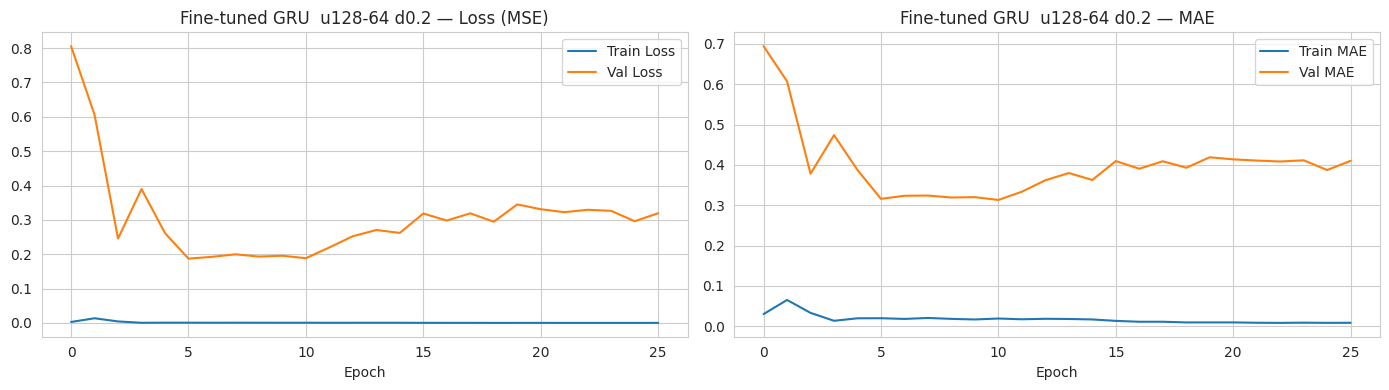

In [33]:
best_row = tune_df.iloc[0]
best_cfg = [c for c in configs if c[0] == BEST_NAME][0]
_, b_cell, b_units, b_dr, b_lr, b_bs = best_cfg
print('Fine-tuning:', BEST_NAME, '| cell=%s units=%s dropout=%.1f' % (b_cell, b_units, b_dr))

tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
final_model = build_rnn(b_cell, units=b_units, dropout=b_dr,
                        learning_rate=b_lr, input_shape=INPUT_SHAPE)

history_final = final_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150, batch_size=b_bs, shuffle=False, verbose=1,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-7, verbose=1),
        ModelCheckpoint('best_final_model.keras', monitor='val_loss', save_best_only=True)
    ]
)

plot_history(history_final, f'Fine-tuned {BEST_NAME}')

                                            Value
Model                Fine-tuned GRU  u128-64 d0.2
RMSE                                    96.361097
MAE                                     83.000923
MAPE (%)                                49.760342
R2                                      -2.274638
Directional Acc (%)                     50.269179


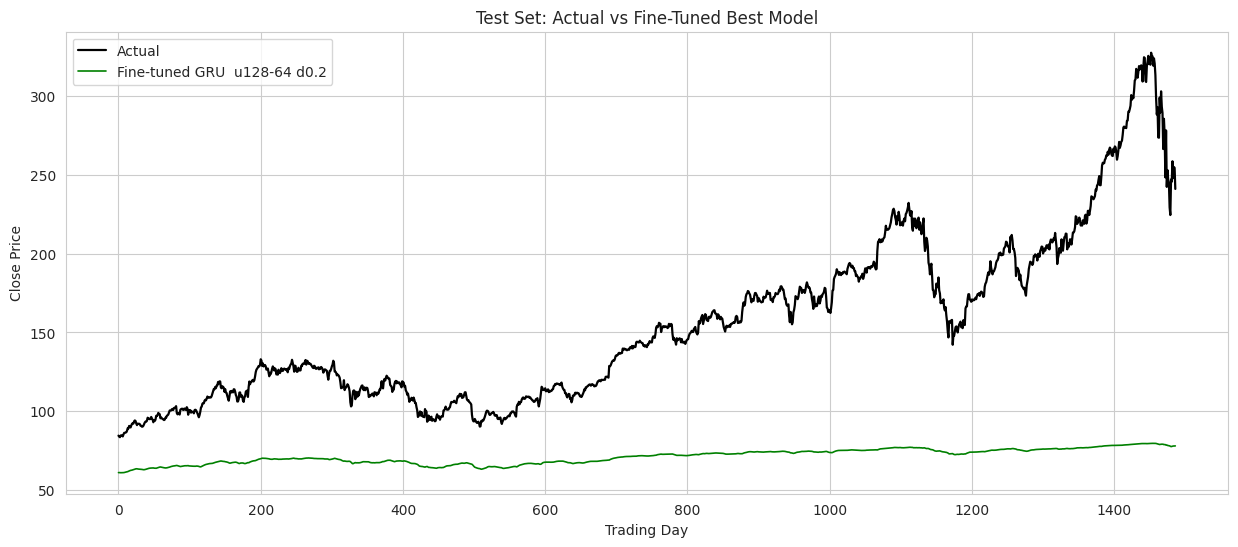

In [34]:
res_final, y_true_f, y_pred_final = evaluate(final_model, X_test, y_test, f'Fine-tuned {BEST_NAME}')
print(pd.Series(res_final).to_frame('Value').round(4))

plt.figure(figsize=(15,6))
plt.plot(y_true_f, label='Actual', color='black', linewidth=1.6)
plt.plot(y_pred_final, label=f'Fine-tuned {BEST_NAME}', color='green', linewidth=1.2)
plt.title('Test Set: Actual vs Fine-Tuned Best Model')
plt.xlabel('Trading Day'); plt.ylabel('Close Price'); plt.legend(); plt.show()

## 14. Final Results Comparison Table

,RMSE,MAE,MAPE (%),R2,Directional Acc (%)
Model,,,,,
LSTM (baseline),106.3176,93.1445,56.557800,-2.9863,51.6824
GRU (baseline),103.0224,90.0626,54.596901,-2.7430,50.6057
Fine-tuned GRU u128-64 d0.2,96.3611,83.0009,49.760300,-2.2746,50.2692


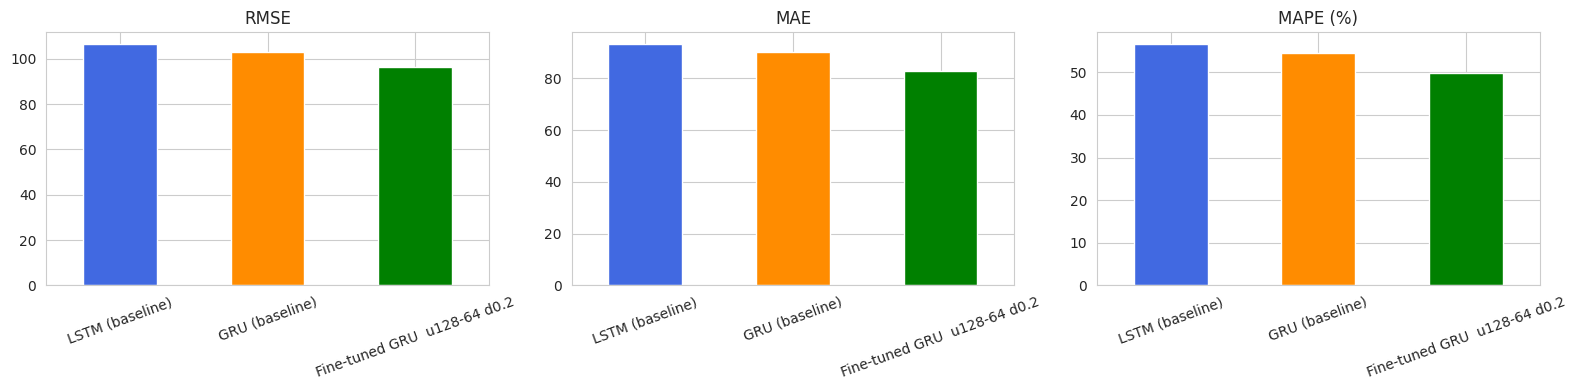

In [35]:
final_table = pd.DataFrame([res_lstm, res_gru, res_final])
final_table = final_table.set_index('Model')
display(final_table.round(4))

# Bar chart comparison of key metrics
metrics_to_plot = ['RMSE', 'MAE', 'MAPE (%)']
fig, axes = plt.subplots(1, 3, figsize=(16,4))
for ax, met in zip(axes, metrics_to_plot):
    final_table[met].plot(kind='bar', ax=ax, color=['royalblue','darkorange','green'])
    ax.set_title(met); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

In [36]:
# Efficiency comparison: parameters and training time proxy (epochs to converge)
eff = pd.DataFrame([
    {'Model':'LSTM (baseline)', 'Parameters': lstm_model.count_params(),
     'Epochs to Best': int(np.argmin(history_lstm.history['val_loss']))+1,
     'Best Val Loss': min(history_lstm.history['val_loss'])},
    {'Model':'GRU (baseline)',  'Parameters': gru_model.count_params(),
     'Epochs to Best': int(np.argmin(history_gru.history['val_loss']))+1,
     'Best Val Loss': min(history_gru.history['val_loss'])},
])
eff.round(6)

,Model,Parameters,Epochs to Best,Best Val Loss
0,LSTM (baseline),29857,26,0.304064
1,GRU (baseline),22817,4,0.279331


In [37]:
# Save the final model for deployment
final_model.save('final_stock_model.keras')
print('Model saved as final_stock_model.keras')

# Export results table
final_table.to_csv('model_comparison_results.csv')
tune_df.to_csv('hyperparameter_tuning_results.csv', index=False)
print('Results exported to CSV.')

Model saved as final_stock_model.keras
Results exported to CSV.
